In [2]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

# 2. Симуляции в Python

## Задание 2.1 Нормальная выборка

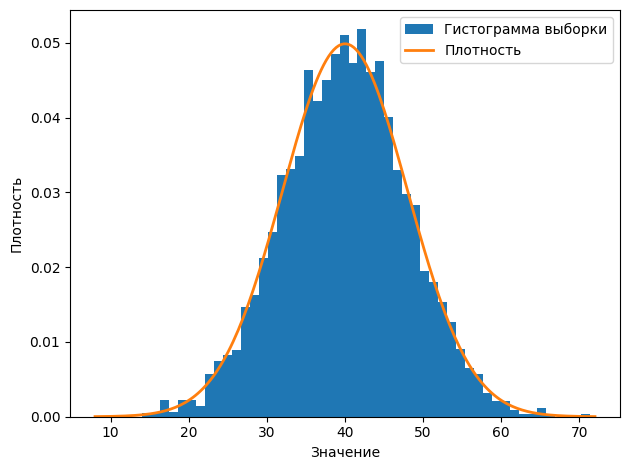

Среднее по выборке: 40.04481544070059
std по выборке: 7.971041406841272


In [3]:
mu, sigma = 40, 8
np.random.seed(42)
sample = np.random.normal(mu, sigma, size=5000)
x = np.linspace(mu - 4*sigma, mu + 4*sigma, 200)

plt.hist(sample, bins=50, density=True, label="Гистограмма выборки")
plt.plot(x, stats.norm.pdf(x, mu, sigma), color="tab:orange", linewidth=2, label="Плотность")

plt.xlabel("Значение")
plt.ylabel("Плотность")
plt.legend()
plt.tight_layout()
plt.show()

print("Среднее по выборке:", sample.mean())
print("std по выборке:", sample.std())

### Вывод

- **Среднее выборки:** 40,045 при заданном 40.
- **Стандартное отклонение выборки:** 7,971 при заданном 8.

Оба значения близки к заданным. Небольшие расхождения ожидаемы, потому что выборка случайная



## Задание 2.2 Биномиальная выборка

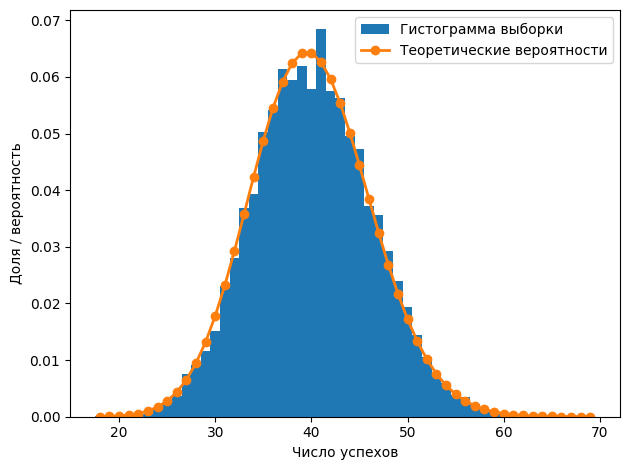

Среднее по выборке: 40.1998
std по выборке: 6.193018646831285
Теоретическое среднее: 40.0
Теоретическое std: 6.196773353931867


In [11]:
n, p = 1000, 0.04
np.random.seed(42)
sample = np.random.binomial(n, p, size=5000)
k = np.arange(sample.min(), sample.max() + 1)
bins = np.append(k - 0.5, k[-1] + 0.5)

plt.hist(sample, bins=bins, density=True, label="Гистограмма выборки")
plt.plot(k, stats.binom.pmf(k, n, p), "o-", color="tab:orange", linewidth=2, label="Теоретические вероятности")

plt.xlabel("Число успехов")
plt.ylabel("Доля / вероятность")
plt.legend()
plt.tight_layout()
plt.show()

print("Среднее по выборке:", sample.mean())
print("std по выборке:", sample.std())

# Теоретический подсчёт
mx = 1000 * 0.04
stdx = (1000 * 0.04 * 0.96) ** 0.5

print("Теоретическое среднее:", mx)
print("Теоретическое std:", stdx)

### Вывод

**Среднее** по выборке составило **40,2** при теоретическом значении 40.
**Стандартное отклонение** по выборке составило **6,193**, при теоретическом значении 6,197. Оба показателя близки к теоретическим значениям. Небольшие расхождения допустимы, выборка случайная.



## Задание 2.3. ЦПТ на экспоненциальном распределении

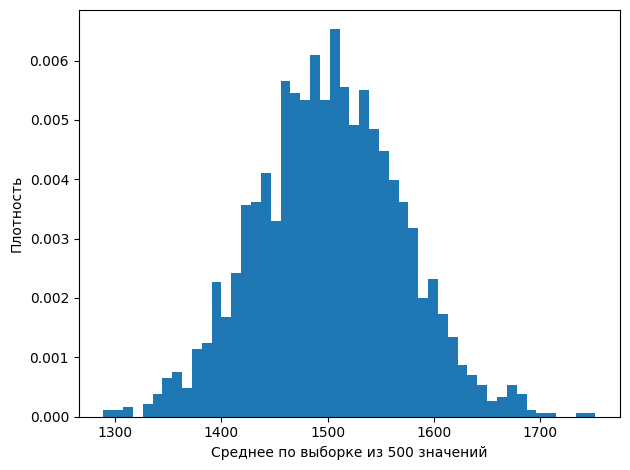

In [5]:
np.random.seed(42)
means = []

for _ in range(2002):
  sample = np.random.exponential(scale=1500, size=500)
  means.append(sample.mean())

plt.hist(means, bins=50, density=True)
plt.xlabel("Среднее по выборке из 500 значений")
plt.ylabel("Плотность")
plt.tight_layout()
plt.show()


### Вывод

Гистограмма 2002 выборочных средних напоминает колокол с центром около 1500. Исходные значения имеют асимметричное экспоненциальное распределение, но каждое среднее рассчитано по 500 независимым значениям. По центральной предельной теореме распределение таких средних приближается к нормальному.

# 3. Мини-кейс про кнопку

## 3.1 Посчитать по формуле

Стандартную ошибку конверсии считаем по формуле $SE = \sqrt{\hat p(1-\hat p)/n}$, где $\hat p$ обозначает наблюдаемую конверсию, а $n$ обозначает число соискателей в группе.

Для старой кнопки конверсия равна 155/5000 = 0,031. Для новой кнопки она равна 170/5000 = 0,034. Чтобы выразить стандартные ошибки и разницу конверсий в процентных пунктах, умножаем их на 100.

In [6]:
n_old, n_new = 5000, 5000
p_old = 155 / n_old
p_new = 170 / n_new

se_old = (p_old * (1 - p_old) / n_old) ** 0.5
se_new = (p_new * (1 - p_new) / n_new) ** 0.5

difference = p_new - p_old
se_difference = (se_old**2 + se_new**2) ** 0.5

print(f"Стандартная ошибка для старой кнопки: {se_old * 100:.3f} п.п.")
print(f"Стандартная ошибка для новой кнопки: {se_new * 100:.3f} п.п.")
print(f"Разница конверсий: {difference * 100:.3f} п.п.")
print(f"Стандартная ошибка разницы: {se_difference * 100:.3f} п.п.")

Стандартная ошибка для старой кнопки: 0.245 п.п.
Стандартная ошибка для новой кнопки: 0.256 п.п.
Разница конверсий: 0.300 п.п.
Стандартная ошибка разницы: 0.355 п.п.


Стандартная ошибка конверсии составила 0,245 п.п. для старой кнопки и 0,256 п.п. для новой. Наблюдаемая разница в 0,3 п.п. немного больше каждой из этих ошибок по отдельности.

При сравнении двух конверсий нужно учесть, что обе оценки колеблются. Если считать группы независимыми, стандартная ошибка их разницы составляет 0,355 п.п. Наблюдаемая разница меньше этой ошибки, поэтому по этим данным пока нельзя уверенно сказать, что новая кнопка повышает конверсию.


## 3.2 Проверить симуляцией

Предположим, что цвет кнопки не влияет на вероятность отклика, поэтому она одинакова в обеих группах. Оценим эту общую вероятность по объединённым данным: (155 + 170) / (5000 + 5000) = 0,0325 = 3,25%. В симуляции будем использовать вероятность отклика 3,25% для обеих групп.

In [7]:
np.random.seed(42)

n = 5000
p = 0.0325
n_simulations = 10000

old_clicks = np.random.binomial(n, p, size=n_simulations)
new_clicks = np.random.binomial(n, p, size=n_simulations)

click_differences = new_clicks - old_clicks
differences_pp = click_differences / n * 100

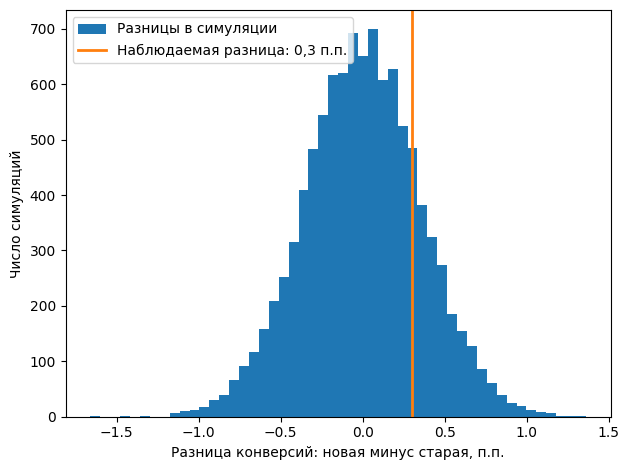

Доля симуляций с разницей 0,3 п.п. или больше: 20.35%


In [8]:
observed_click_difference = 170 - 155
observed_difference_pp = observed_click_difference / n * 100

plt.hist(differences_pp, bins=50, label="Разницы в симуляции")
plt.axvline(observed_difference_pp, color="tab:orange", linewidth=2,
            label="Наблюдаемая разница: 0,3 п.п.")

plt.xlabel("Разница конверсий: новая минус старая, п.п.")
plt.ylabel("Число симуляций")
plt.legend()
plt.tight_layout()
plt.show()

frequency = (click_differences >= observed_click_difference).mean()
print(f"Доля симуляций с разницей 0,3 п.п. или больше: {frequency:.2%}")

При одинаковой вероятности отклика в обеих группах новая кнопка опережала старую на 0,3 п.п. или больше в 20,35% симуляций. Такая разница вполне объяснима случайным шумом. По этим данным нельзя уверенно утверждать, что новая кнопка повышает конверсию.

## Задание 3.3. Выбросы во времени сессий

In [10]:
x = np.array([3, 4, 4, 5, 5, 6, 6, 7, 8, 52])

upper_3s = x.mean() + 3 * x.std(ddof=1)
outliers_3s = x[x > upper_3s]

p25, p75 = np.percentile(x, [25, 75])
upper_pct = p75 + 1.5 * (p75 - p25)
outliers_pct = x[x > upper_pct]

print(outliers_3s)
print(outliers_pct)

[]
[52]


**Правило трёх сигм**

Сначала находим среднее. Складываем все значения и делим на 10. Получаю 100/10 = 10 минут.

Считаем, насколько каждое значение отклоняется от 10, и возводим отклонения в квадрат. Сумма квадратов равна 49+36+36+25+25+16+16+9+4+1764=1980.

Как и в коде с ddof=1, делим на 10-1=9 и берём корень. Стандартное отклонение получается $\sqrt{1980/9}≈14,83$ минуты.

Прибавляем к среднему три стандартных отклонения. Верхняя граница получается $10+3*14,83 ≈ 54,5$ минуты. Самая длинная сессия, 52 минуты, ниже этой границы. Выбросов по этому правилу нет.

**Метод по квартилям**

Чтобы получить те же квартили, что и в Python, нумеруeм отсортированные значения от 0 до 9. Позицию первого квартиля находим как 9 * 0,25=2,25. Между значениями 4 и 5 проходим четверть расстояния и получаю $Q_1=4,25$.

Позицию третьего квартиля находим как 9*0,75=6,75. Между значениями 6 и 7 проходим три четверти расстояния и получаю $Q_3=6,75$.

Вычитаем первый квартиль из третьего. Межквартильный размах равен $6,75-4,25=2,5$ минуты. Прибавляем к третьему квартилю полтора таких размаха и получаю верхнюю границу $6,75+1,5*2,5=10,5$ минуты. Эту границу превышает только сессия в 52 минуты.

На этих данных метод по квартилям сработал лучше. Сессия в 52 минуты увеличила среднее и стандартное отклонение, поэтому граница трёх сигм поднялась выше 52. Квартили определяются по значениям ближе к середине ряда, поэтому верхняя граница осталась достаточно низкой, чтобы выделить эту сессию.